# 例4-10 使用matplotlib绘制直方图


(37748736,)
[7 7 7 ... 3 1 2]


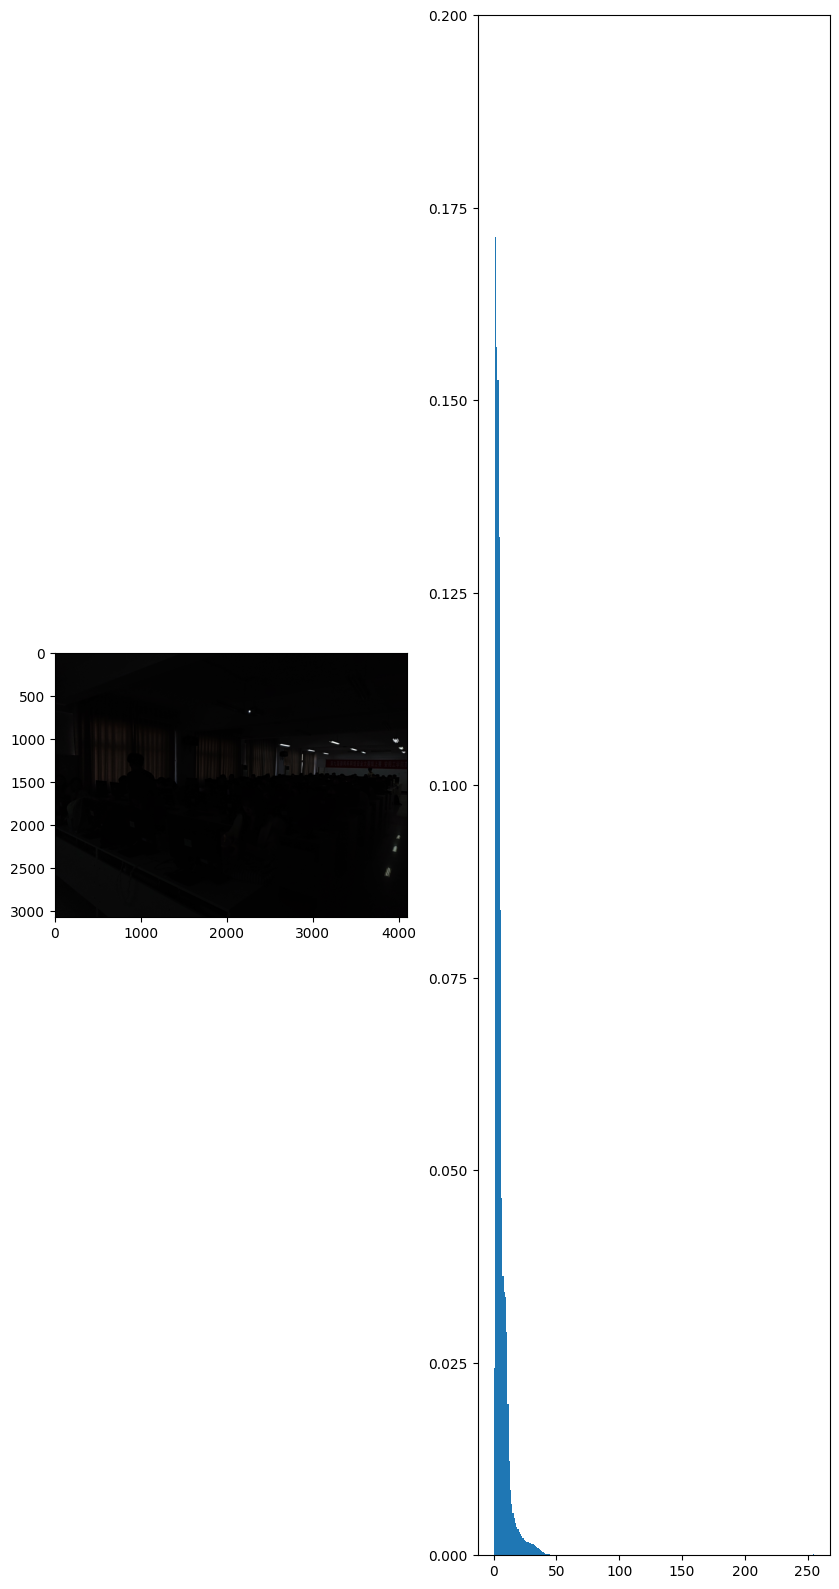

In [1]:
import sys 
sys.path.append('/home/aistudio/external-libraries')
import numpy as np 
import matplotlib.pyplot as plt
from PIL import Image
from skimage import util
path = '/home/aistudio/'
image_pil = Image.open(path+'class_a.jpg')
image = np.array(image_pil)
image_1d = image.ravel()
print(image_1d.shape)
print(image_1d)

fig,axes = plt.subplots(1,2,figsize=(10,20))
#plt.subplot(1,2,1) 
axes[0].imshow(image)
#plt.subplot(1,2,2)
axes[1].hist(image_1d,bins=256,range=[0,255],density = True,weights = None,cumulative = False) 
axes[1].set_ylim(0,0.2)

plt.show()



(3072, 4096)


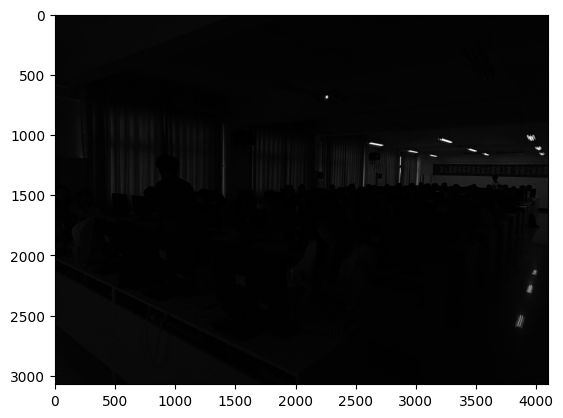

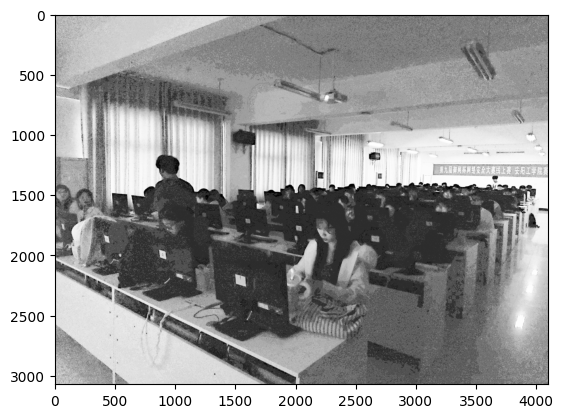

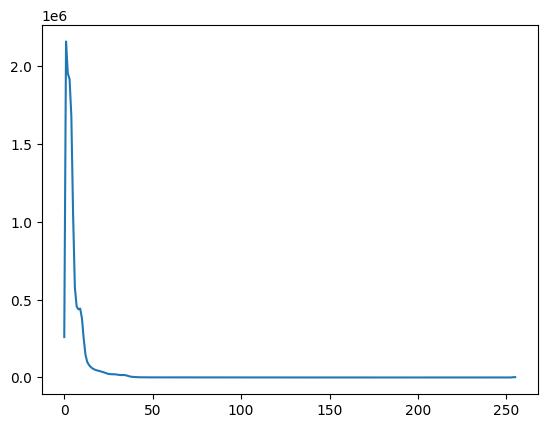

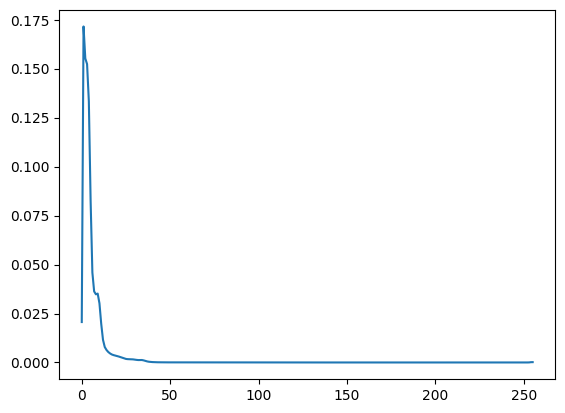

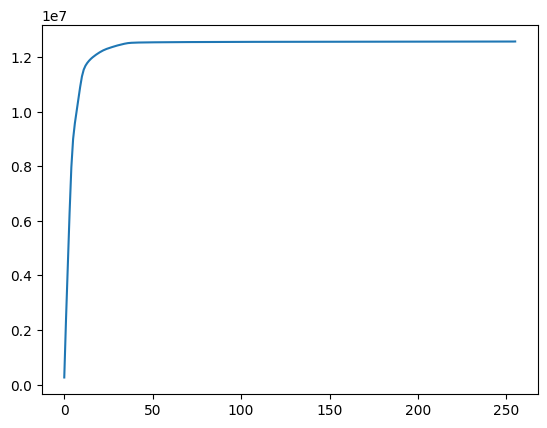

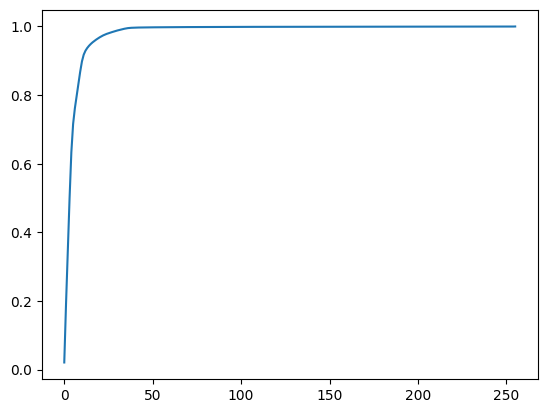

In [8]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

def histogram(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    originHist = np.zeros((256,),np.int32)
    for i in range(0,rows):
        for j in range(0,cols):
            gray_value = image_gray[i,j]
            originHist[gray_value] = originHist[gray_value] + 1
    return originHist 

def pdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    originHist = histogram(image_gray)
    pdf_list = np.zeros((256,),np.float64)
    pdf_list = originHist.astype(np.float64)/float(totalPixel)
    return pdf_list


def cumulative_histogram(image_gray):
    originHist = histogram(image_gray)
    cumuHist = originHist.copy()
    summ = 0
    for i in range(0,len(originHist)):
        summ = summ + originHist[i]
        cumuHist[i] = summ
    return cumuHist



def cdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    cumuHist = cumulative_histogram(image_gray)
    cdf_list = np.zeros((256,),np.float64)
    cdf_list = cumuHist.astype(np.float64)/float(totalPixel)
    return cdf_list


def equlized_hist(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    image_equalized = np.zeros_like(image_gray,dtype=np.uint8)
    cdf_list = cdf(image_gray)
    for i in range(0,rows):
        for j in range(0,cols):
            value = image_gray[i,j]
            new_value = cdf_list[value] * 255.0
            image_equalized[i,j]=int(new_value)
    return image_equalized




path = '/home/aistudio/'
image_bgr = cv2.imread(path + 'class_a.jpg')
image_gray = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2GRAY)
print(image_gray.shape)
plt.imshow(image_gray,'gray')
plt.show()
plt.imshow(equlized_hist(image_gray),'gray')
plt.show()
plt.plot(histogram(image_gray))
plt.show()
plt.plot(pdf(image_gray))
plt.show()
plt.plot(cumulative_histogram(image_gray))
plt.show()
plt.plot(cdf(image_gray))
plt.show()

In [9]:
equal_gray = equlized_hist(image_gray)

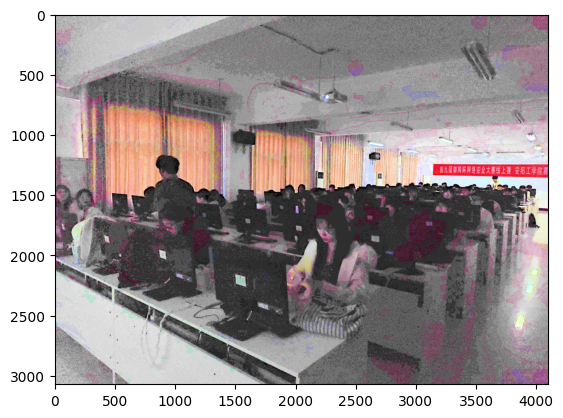

In [11]:
hsv = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2HSV)
h,s,v = cv2.split(hsv)
image_gray = v
equal_gray = equlized_hist(image_gray)
newV= equal_gray
newHSV = cv2.merge([h,s,newV])
equal_rgb = cv2.cvtColor(newHSV,cv2.COLOR_HSV2RGB)
plt.imshow(equal_rgb)
plt.show()
#print(equal_gray)